# Loading the Datasets

## 1.1 Load both datasets from scikit-learn

In [60]:

from sklearn.datasets import load_wine

load_data = load_wine()


In [61]:
import pandas as pd #tablolar için
import numpy as np #sayısal işlemler için
import matplotlib.pyplot as plt #grafik çizimleri için
import seaborn as sns #ısı haitası için 
from sklearn.datasets import load_wine; #veri setini yüklemek içi kullandım
from sklearn.model_selection import train_test_split #veri setini eğitim ve test olarak ayırmak için kullandım
#import hücresi
SEEDS=[42,52,62] # Eğitim ve validation bölmelerini tekrarlamak için kullanılan rastgelelik tohumları
from sklearn.preprocessing import StandardScaler
#7.bölüm için modelin bulunduğu kütüphaneleri import ettim
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score  #modellerin başarı ölçüleri
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

In [62]:
# Wine veri setindeki üç sınıfın isimlerini gösterir.
# Sınıflar 0, 1 ve 2 olarak kodlanmıştır.
# Bunlar üç farklı şarap grubunu temsil eder.

from sklearn.datasets import load_wine

wine_data = load_wine()
print(wine_data.target_names)

['class_0' 'class_1' 'class_2']


In [63]:
# Wine veri setindeki 13 özelliğin isimlerini gösterir.
from sklearn.datasets import load_wine

wine_data = load_wine()
print(wine_data.feature_names)

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [64]:
load_data.data
# ölçümleri verir 

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]], shape=(178, 13))

## 1.2 Create the data frames

In [65]:
X = pd.DataFrame(
    load_data.data,
    columns=load_data.feature_names
)

# Şarap örneklerinin ait olduğu sınıflar (0, 1, 2)
Y = load_data.target

# İlk 5 şarap örneğini göster
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [66]:
X.shape
#Satır ve süun sayısı bilgisini öğrendik.

(178, 13)

In [67]:
pd.Series(Y).value_counts() 
#0 ve 1 olarak yani ,y, huylu ve kötü huylu olarak kaç hastaya sahibiz

1    71
0    59
2    48
Name: count, dtype: int64

Wine veri seti, 178 şarap örneğinden ve her örnek için ölçülmüş 13 sayısal özellikten oluşmaktadır. Örnekler üç farklı sınıfa ayrılmaktadır. Veri seti, sınıflandırma ve kümeleme algoritmalarını karşılaştırmak amacıyla kullanılacaktır.

Sınıf dağılımı:
- Sınıf 0: 59 örnek
- Sınıf 1: 71 örnek
- Sınıf 2: 48 örnek

# 2. Dataset Quality Checks

## 2.1 Missing values and duplicates

In [68]:
X.isnull().sum()
#her hücreyi içi boş mu kontrol eder ve o sütundaki boş hücre sayısını gösterir

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

In [69]:
X.duplicated().sum()
#bu satırınaynısı var mı kontol eder ve kaç tane aynı satır oldugunu verir

np.int64(0)

eksik değer ve takrar eden değer yok bu yüzden doldurma ve silme işlemi yapmamıza gerek yok

## 2.2 Potential outliers

In [70]:
# Birinci ve üçüncü çeyrek değerlerini hesapla
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

# Çeyrekler arası aralık
IQR = Q3 - Q1

IQR

alcohol                           1.3150
malic_acid                        1.4800
ash                               0.3475
alcalinity_of_ash                 4.3000
magnesium                        19.0000
total_phenols                     1.0575
flavanoids                        1.6700
nonflavanoid_phenols              0.1675
proanthocyanins                   0.7000
color_intensity                   2.9800
hue                               0.3375
od280/od315_of_diluted_wines      1.2325
proline                         484.5000
dtype: float64

In [71]:
# IQR yöntemine göre alt ve üst sınırları hesapla
alt = Q1 - 1.5 * IQR
ust = Q3 + 1.5 * IQR

# Her özellik için aykırı değer sayısını hesapla
aykiri_sayisi = ((X < alt) | (X > ust)).sum()

# En fazla aykırı değer içeren özellikleri göster
aykiri_sayisi.sort_values(ascending=False)

magnesium                       4
alcalinity_of_ash               4
color_intensity                 4
malic_acid                      3
ash                             3
proanthocyanins                 2
hue                             1
alcohol                         0
total_phenols                   0
nonflavanoid_phenols            0
flavanoids                      0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

### Aykırı Değerlerin Değerlendirilmesi

Wine veri setindeki 13 sayısal özellik, IQR yöntemi kullanılarak potansiyel aykırı değerler açısından incelenmiştir.

Aykırı değerler, özellikle uzaklık temelli KNN ve küme merkezlerini kullanan K-Means algoritmalarının sonuçlarını etkileyebilir. Gaussian Naive Bayes algoritması da özelliklerin dağılımını modellediği için uç değerlerden etkilenebilir.

Decision Tree algoritması, özellikler üzerinde eşik değerlerine dayalı bölmeler yaptığı için genel olarak özellik ölçeklerinden daha az etkilenir. Ancak aykırı değerlerin karar sınırlarını etkilemesi mümkündür.

Bu çalışmada aykırı değerler otomatik olarak silinmemiştir. Veri setinin orijinal yapısı korunarak modellerin performansları karşılaştırılmıştır.


## 2.3 Data Types 

In [72]:
X.dtypes # her sütun ne tür sayı tutuyor 

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

In [73]:
X.select_dtypes(include='number').shape[1]#sadee sayı gösteren sütunların sayısını söyler 

13

In [74]:
X.select_dtypes(include='object').shape[1]#sadee yazı gösteren sütunların sayısını söyler 

0

Wine veri setinde 13 özellik bulunmaktadır. Özelliklerin tamamı `float64` veri tipindedir. Kategorik özellik bulunmamaktadır. Bu nedenle kategorik değişkenler için ek bir kodlama işlemine ihtiyaç yoktur.

# 3. Exploratory Data Analysis (EDA)

## 3.1 Descriptive statistics

In [75]:
X.describe() #her sütun için tanımlayıcı bazı istatistikleri tablo şeklinde verir.

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


## 3.2 Class disttribution and correlation 

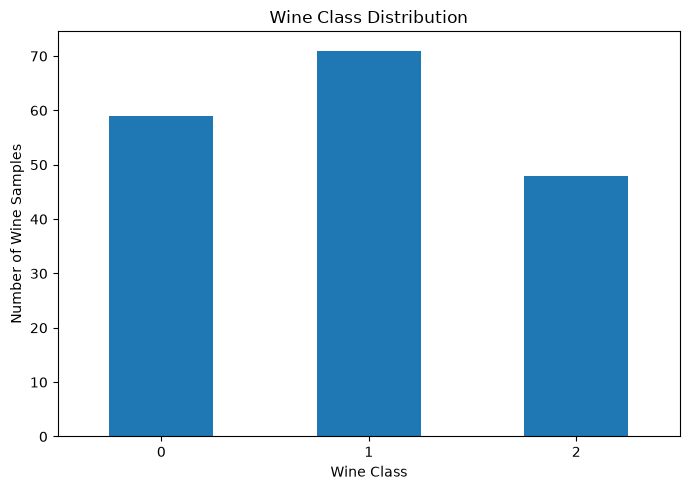

0    59
1    71
2    48
Name: count, dtype: int64


In [76]:
# Wine veri setindeki üç sınıfın örnek sayılarını göster
class_counts = pd.Series(Y).value_counts().sort_index()

plt.figure(figsize=(7, 5))
class_counts.plot(kind="bar")

plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Wine Samples")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("figures/wine_class_distribution.png")
plt.show()

print(class_counts)

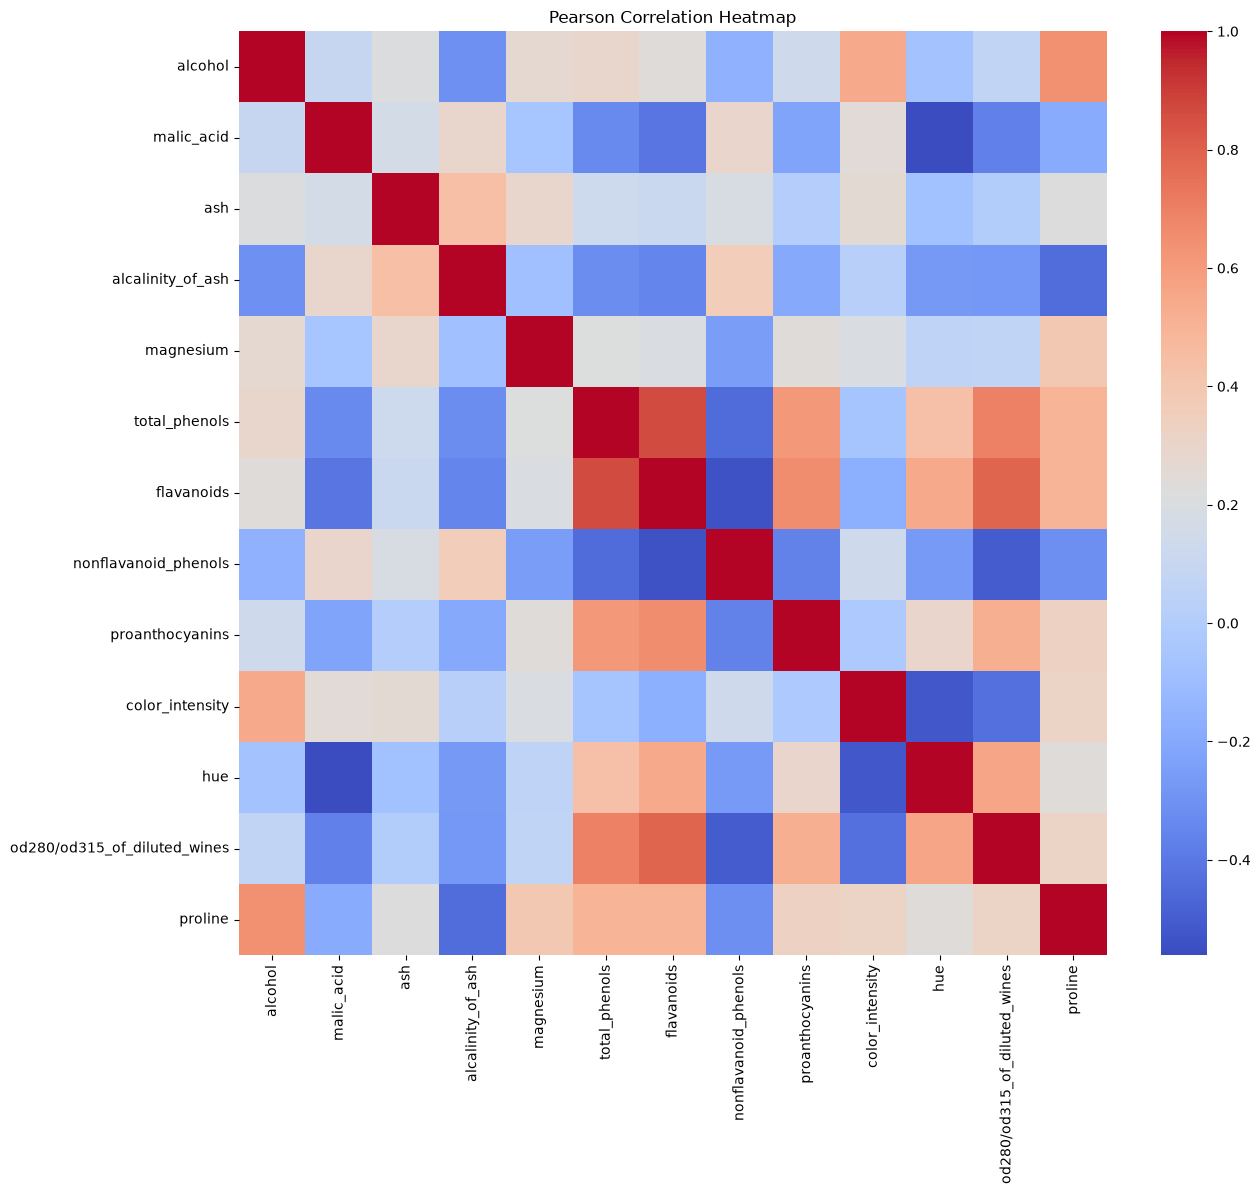

In [77]:
corra=X.corr() #sütunlar arasındaki korelasyonları hesaplıyoruz
plt.figure(figsize=(14,12)) #grafiğin boyutunu ayarladık
sns.heatmap(corra,cmap="coolwarm") #seaborn ile ısı haritasını çizdik renklendirmeyi cmap ile yaptık
plt.title("Pearson Correlation Heatmap") #grafiğe başlık ekledik
plt.savefig("figures/wine_correlation_heatmap.png") #grafiği kaydettik
plt.show() 

In [78]:
corra_abs=corra.abs() #korelasyon değerleriinin mutlak değerini aldık
ust =np.triu(np.ones(corra.shape),k=1).astype(bool)
ciftler= corra_abs.where(ust).stack()
sonuc =ciftler.sort_values(ascending=False).head(3)
sonuc

total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
dtype: float64

### Korelasyon Analizi

Wine veri setindeki 13 sayısal özellik arasındaki Pearson korelasyonları incelenmiştir.

Mutlak korelasyonu en yüksek üç özellik çifti şunlardır:

1. `total_phenols` – `flavanoids`: yaklaşık 0.865
2. `flavanoids` – `od280/od315_of_diluted_wines`: yaklaşık 0.787
3. `total_phenols` – `od280/od315_of_diluted_wines`: yaklaşık 0.700

Bu özellik çiftleri arasında pozitif ve güçlü ilişkiler bulunmaktadır. Özellikle fenolik bileşiklerle ilişkili özelliklerin birlikte değişme eğiliminde olduğu görülmektedir.

Yüksek korelasyon, bazı özelliklerin benzer bilgiler taşıyabileceğini gösterir. Ancak korelasyon tek başına nedensellik anlamına gelmez.

## 3.3 Boxplots

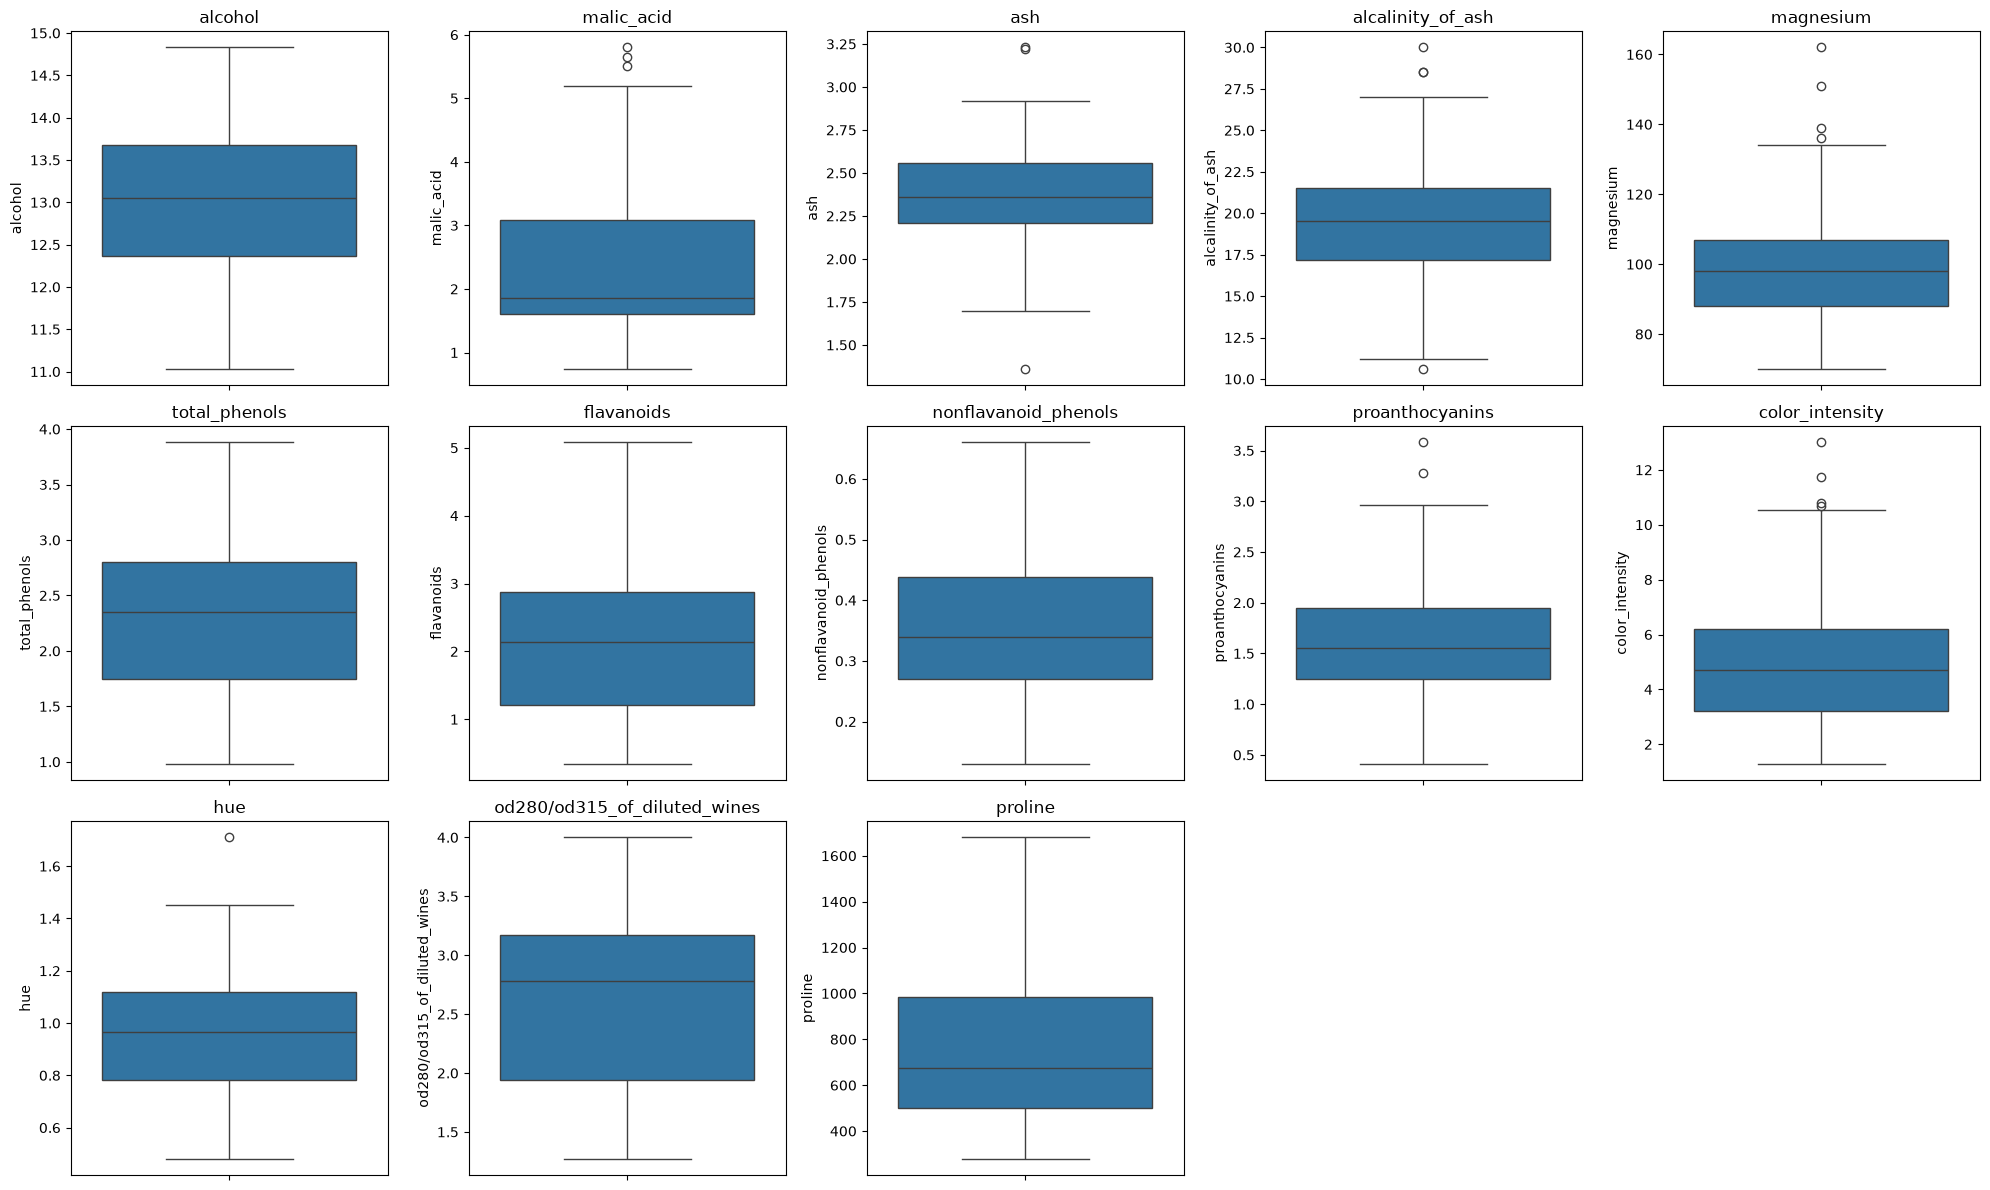

In [79]:
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()
for i, column in enumerate(X.columns):
    sns.boxplot(y=X[column], ax=axes[i])
    axes[i].set_title(column)
for j in range(len(X.columns), len(axes)):   # 15 alandan 13'ü dolu, kalan 2'sini gizle
    axes[j].set_visible(False)
plt.tight_layout()
plt.savefig("figures/wine_boxplots.png")
plt.show()

### Boxplot Analizi

Wine veri setindeki 13 sayısal özelliğin dağılımları boxplot grafikleriyle incelenmiştir.

Özelliklerin değer aralıkları birbirinden farklıdır. Örneğin `proline` özelliği yüzler seviyesinde değerler alırken `hue` ve `nonflavanoid_phenols` gibi özellikler daha küçük sayısal aralıklarda bulunmaktadır.

Bazı özelliklerin boxplot grafiklerinde potansiyel aykırı değerler görülmektedir. Bu değerler özellikle uzaklık hesaplayan KNN ve küme merkezlerine dayanan K-Means algoritmalarını etkileyebilir.

Özelliklerin farklı ölçeklerde olması nedeniyle çalışmanın ilerleyen bölümlerinde StandardScaler kullanılarak ölçeklendirilmiş ve ölçeklendirilmemiş veriler karşılaştırılacaktır.

# 4. Splitting the Datasets

# 4.1 Fix the test set and repeat the training/validation split

In [80]:
# Wine veri setinin %20'sini sabit test kümesi olarak ayır
# stratify=Y ile üç sınıfın oranlarını koru
# random_state=42 ile test kümesini sabitle

X_trval, X_test, y_trval, y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    stratify=Y,
    random_state=42
)

X_test.shape

(36, 13)

In [81]:
# Kalan 142 şarap örneğini üç farklı seed ile
# eğitim (%70) ve validation (%10) kümelerine ayır

splits = {}

for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_trval,
        y_trval,
        test_size=0.125,
        stratify=y_trval,
        random_state=seed
    )

    splits[seed] = {
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y_train,
        "y_val": y_val
    }

splits[42]["X_train"].shape

(124, 13)

## 4.2 Verify the split

In [82]:
rows = []   # tablonun satırlarını toplayacağımız liste
for seed in SEEDS:   # her seed için
    # bu seed'in train, validation ve test parçaları
    parcalar = {"train": (splits[seed]["X_train"], splits[seed]["y_train"]),
                "val": (splits[seed]["X_val"], splits[seed]["y_val"]),
                "test": (X_test, y_test)}
    for isim, (Xp, yp) in parcalar.items():   # her parça için bir satır
        rows.append({"seed": seed, "subset": isim, "count": len(Xp),   # hasta sayısı
                     "percent": round(len(Xp) / len(X) * 100, 1),       # tüm verinin yüzdesi
                     # her sınıf için ayrı sütun: class 0, class 1, class 2
                     **{f"class {c}": (yp == c).sum() for c in np.unique(Y)}})
split_summary = pd.DataFrame(rows)   # listeyi tabloya çevir
split_summary

,seed,subset,count,percent,class 0,class 1,class 2
0,42,train,124,69.7,41,50,33
1,42,val,18,10.1,6,7,5
2,42,test,36,20.2,12,14,10
3,52,train,124,69.7,41,50,33
4,52,val,18,10.1,6,7,5
5,52,test,36,20.2,12,14,10
6,62,train,124,69.7,41,50,33
7,62,val,18,10.1,6,7,5
8,62,test,36,20.2,12,14,10


In [83]:
# Her seed için veri kümelerinin çakışmadığını kontrol et

for seed in SEEDS:
    tr = splits[seed]["X_train"]
    va = splits[seed]["X_val"]

    train_idx = set(tr.index)
    val_idx = set(va.index)
    test_idx = set(X_test.index)

    assert train_idx.isdisjoint(val_idx)
    assert train_idx.isdisjoint(test_idx)
    assert val_idx.isdisjoint(test_idx)

    assert train_idx | val_idx | test_idx == set(X.index)

    assert len(tr) == 124
    assert len(va) == 18
    assert len(X_test) == 36

    print(f"Seed {seed}: Tüm kontroller başarılı")

print("\nToplam örnek sayısı:", len(X))
print("Sabit test örnek sayısı:", len(X_test))

Seed 42: Tüm kontroller başarılı
Seed 52: Tüm kontroller başarılı
Seed 62: Tüm kontroller başarılı

Toplam örnek sayısı: 178
Sabit test örnek sayısı: 36


### Veri Bölme Kontrolleri

Wine veri setindeki 178 örneğin %20'si (36 örnek), `random_state=42` kullanılarak sabit test kümesi olarak ayrılmıştır.

Kalan 142 örnek, 42, 52 ve 62 seed değerleri kullanılarak üç kez eğitim ve validation kümelerine bölünmüştür.

Her bölmede:
- Eğitim: 124 örnek
- Validation: 18 örnek
- Test: 36 örnek

Eğitim, validation ve test kümelerinin indeksleri arasında çakışma bulunmamaktadır. `stratify` parametresi kullanılarak üç sınıfın oranları mümkün olduğunca korunmuştur.

Test kümesi bütün deneylerde sabit tutulmuştur.

# 5. Data Preprocessing and Scaling

## 5.1 Handle missing values, if present
2.1'de eksik değer olmadığını gördük, bu yüzden imputation adımı eklemedik.

### StandardScaler Seçimi

Wine veri setindeki özellikler farklı sayısal ölçeklere sahiptir. Örneğin `proline` yüzler seviyesinde değerler alırken `hue` ve `nonflavanoid_phenols` daha küçük değer aralıklarında bulunmaktadır.

Bu nedenle StandardScaler kullanılmıştır. StandardScaler, eğitim verisinden hesaplanan ortalama ve standart sapmaya göre her özelliği dönüştürür.

Ölçeklendirme, özellikle uzaklık temelli KNN ve K-Means algoritmalarında büyük sayısal değerlere sahip özelliklerin baskın olmasını azaltmaya yardımcı olur.

Veri sızıntısını önlemek için scaler yalnızca eğitim verisine fit edilmeli; validation ve test verileri eğitimden öğrenilen parametrelerle dönüştürülmelidir.

## 5.3 Fit and apply the scaler correctly

In [84]:
scalers = {}
for seed in SEEDS:
    scaler = StandardScaler() # her seed için yeni scaler
    scaler.fit(splits[seed]["X_train"]) # sadece train'den öğren
    splits[seed]["X_train_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_train"]),
        columns=X.columns, index=splits[seed]["X_train"].index)
    splits[seed]["X_val_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_val"]),
        columns=X.columns, index=splits[seed]["X_val"].index)
    scalers[seed] = scaler   # scaler'ı sakla

# test sadece seed 42'nin scaler'ı ile dönüştürülür
X_test_scaled = pd.DataFrame(scalers[42].transform(X_test),
                             columns=X.columns, index=X_test.index)

In [85]:
splits[42]["X_train"].head()   # seed 42, ölçeklemeden önce

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


In [86]:
splits[42]["X_train_scaled"].head()   # seed 42, ölçeklemeden sonra

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


### Ölçeklendirme Öncesi ve Sonrası

Wine veri setinde `proline` gibi özellikler yüzler seviyesinde değerler alırken `hue` ve `nonflavanoid_phenols` gibi özellikler daha küçük sayısal aralıklara sahiptir.

StandardScaler uygulandıktan sonra eğitim verisindeki her özelliğin ortalaması yaklaşık 0, standart sapması yaklaşık 1 olur. Ancak bütün değerlerin -3 ile +3 arasında olması garanti değildir.

Her seed için scaler yalnızca eğitim verisine fit edilmiştir. Validation verisi ilgili seed'in scaler'ı ile, sabit test verisi ise seed 42'nin scaler'ı ile dönüştürülmüştür.

### Ölçeklendirilmiş ve Ölçeklendirilmemiş Veriler

Her seed için iki farklı veri temsili hazırlanmıştır:

- **Unscaled:** Orijinal özellik değerlerini içeren `X_train` ve `X_val`.
- **Scaled:** StandardScaler uygulanmış `X_train_scaled` ve `X_val_scaled`.

Her iki temsil de aynı şarap örneklerini ve aynı sınıf etiketlerini içermektedir. Aralarındaki tek fark özelliklerin ölçeklendirilmiş olmasıdır.

Bu iki veri temsili kullanılarak Decision Tree, KNN, Gaussian Naive Bayes ve K-Means algoritmalarında ölçeklendirmenin performansa etkisi karşılaştırılacaktır.

# 7. Training the Classification Models
## 7.1 Required experiments

In [87]:
import sklearn
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
#kullandığımız paketlerin sürümleri

pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1


In [88]:
# denenecek 11 ayar: 5 ağaç derinliği, 5 komşu sayısı, 1 Naive Bayes
ayarlar = []
for d in [2, 3, 5, 10, None]:
    ayarlar.append(("dt", d))
for k in [1, 3, 5, 7, 11]:
    ayarlar.append(("knn", k))
ayarlar.append(("gnb", None))

# algoritma adına ve ayara göre model oluşturur
def model_olustur(algo, param, seed):
    if algo == "dt":
        return DecisionTreeClassifier(max_depth=param, random_state=seed)
    if algo == "knn":
        return KNeighborsClassifier(n_neighbors=param, weights="uniform", metric="euclidean")
    return GaussianNB()

# ayarı kısa bir etikete çevirir: d3, k5, default
def param_etiketi(algo, param):
    if algo == "dt":
        return f"d{param}"
    if algo == "knn":
        return f"k{param}"
    return "default"

In [89]:
# Wine validation metriklerini hesapla
def hesapla_metrikler(model, Xv, yv):
    tahmin = model.predict(Xv)
    olasilik = model.predict_proba(Xv)

    gercek = np.asarray(yv)

    undefined_precision = []
    undefined_recall = []

    for sinif in model.classes_:
        if np.sum(tahmin == sinif) == 0:
            undefined_precision.append(int(sinif))

        if np.sum(gercek == sinif) == 0:
            undefined_recall.append(int(sinif))

    sonuc = {
        "val_accuracy": accuracy_score(yv, tahmin),
        "val_precision": precision_score(
            yv, tahmin, average="macro", zero_division=0
        ),
        "val_recall": recall_score(
            yv, tahmin, average="macro", zero_division=0
        ),
        "val_f1": f1_score(
            yv, tahmin, average="macro", zero_division=0
        ),
        "undefined_precision_classes": str(undefined_precision),
        "undefined_recall_classes": str(undefined_recall),
    }

    sonuc["val_roc_auc"] = roc_auc_score(
        yv,
        olasilik,
        multi_class="ovr",
        average="macro",
        labels=model.classes_
    )

    return sonuc

## 7.2 Record and compare the experiments

In [90]:
DATASET = "wine"
runs = []          # her eğitimin sonucu buraya
models_s42 = {}    # seed 42 modellerini test için saklıyoruz

for seed in SEEDS:
    for rep in ["unscaled", "scaled"]:
        if rep == "unscaled":
            Xtr, Xv = splits[seed]["X_train"], splits[seed]["X_val"]
        else:
            Xtr, Xv = splits[seed]["X_train_scaled"], splits[seed]["X_val_scaled"]
        ytr, yv = splits[seed]["y_train"], splits[seed]["y_val"]

        for algo, param in ayarlar:
            model = model_olustur(algo, param, seed)
            model.fit(Xtr, ytr)                     # sadece train ile eğit
            etiket = param_etiketi(algo, param)
            config_id = f"{DATASET}_{algo}_{rep}_{etiket}"
            tr_tahmin = model.predict(Xtr)
            satir = {"run_id": f"{config_id}_s{seed}", "config_id": config_id,
                     "dataset": DATASET, "seed": seed, "algorithm": algo,
                     "representation": rep, "param": etiket,
                     "train_accuracy": accuracy_score(ytr, tr_tahmin),
                     "train_f1": f1_score(ytr, tr_tahmin, average="macro")}
            satir.update(hesapla_metrikler(model, Xv, yv))
            runs.append(satir)
            if seed == 42:
                models_s42[config_id] = model

runs_df = pd.DataFrame(runs)
print("Toplam eğitim:", len(runs_df))
runs_df.head()

Toplam eğitim: 66


,run_id,config_id,dataset,seed,algorithm,representation,param,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,undefined_precision_classes,undefined_recall_classes,val_roc_auc
0,wine_dt_unscaled_d2_s42,wine_dt_unscaled_d2,wine,42,dt,unscaled,d2,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,[],[],0.910596
1,wine_dt_unscaled_d3_s42,wine_dt_unscaled_d3,wine,42,dt,unscaled,d3,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,[],[],0.968645
2,wine_dt_unscaled_d5_s42,wine_dt_unscaled_d5,wine,42,dt,unscaled,d5,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],[],0.957071
3,wine_dt_unscaled_d10_s42,wine_dt_unscaled_d10,wine,42,dt,unscaled,d10,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],[],0.957071
4,wine_dt_unscaled_dNone_s42,wine_dt_unscaled_dNone,wine,42,dt,unscaled,dNone,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],[],0.957071


Bu bölümde üç modeli eğittim: Decision Tree , KNN ve Naive Bayes. Her birini hem ölçeksiz hem ölçekli veride, üç farklı seed için çalıştırdım, toplamda 66 model oldu. Modelleri sadece train verisiyle eğittim. Her çalıştırmaya hangi model, hangi ayar ve hangi seed olduğu anlaşılsın diye bir isim verdim. Seed 42'deki modelleri de en sonda test için ayrıca sakladım.

# 8. Measuring Validation Performance

## 8.1 Required Metrics

Modellerin validation performansları accuracy, macro precision, macro recall, macro F1 ve ROC-AUC metrikleriyle değerlendirilmiştir.

Wine veri seti üç sınıflı olduğu için ROC-AUC hesaplamasında One-vs-Rest (OvR) yaklaşımı ve macro ortalama kullanılmıştır. Hesaplamalar sınıf olasılıkları üzerinden yapılmıştır.

Precision ve recall için tanımsız durumlar ayrıca kontrol edilmiş ve sonuç tablolarında kaydedilmiştir.

## 8.2 Comparison Tables and Model Selection

Her model konfigürasyonu üç farklı seed ile değerlendirilmiştir. Sonuçlar ortalama ve standart sapma değerleriyle karşılaştırılmıştır. En iyi konfigürasyon, öncelikle en yüksek ortalama validation macro F1 değerine göre seçilmiştir.

In [91]:
pd.set_option("display.max_rows", 100)   # satırların hepsini ekranda gösterdim
runs_df

,run_id,config_id,dataset,seed,algorithm,representation,param,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,undefined_precision_classes,undefined_recall_classes,val_roc_auc
0,wine_dt_unscaled_d2_s42,wine_dt_unscaled_d2,wine,42,dt,unscaled,d2,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,[],[],0.910596
1,wine_dt_unscaled_d3_s42,wine_dt_unscaled_d3,wine,42,dt,unscaled,d3,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,[],[],0.968645
2,wine_dt_unscaled_d5_s42,wine_dt_unscaled_d5,wine,42,dt,unscaled,d5,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],[],0.957071
3,wine_dt_unscaled_d10_s42,wine_dt_unscaled_d10,wine,42,dt,unscaled,d10,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],[],0.957071
4,wine_dt_unscaled_dNone_s42,wine_dt_unscaled_dNone,wine,42,dt,unscaled,dNone,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],[],0.957071
5,wine_knn_unscaled_k1_s42,wine_knn_unscaled_k1,wine,42,knn,unscaled,k1,1.000000,1.000000,0.666667,0.675000,0.660317,0.664646,[],[],0.745174
6,wine_knn_unscaled_k3_s42,wine_knn_unscaled_k3,wine,42,knn,unscaled,k3,0.846774,0.841468,0.611111,0.611111,0.601587,0.604118,[],[],0.800343
7,wine_knn_unscaled_k5_s42,wine_knn_unscaled_k5,wine,42,knn,unscaled,k5,0.798387,0.783717,0.722222,0.715873,0.715873,0.712821,[],[],0.875905
8,wine_knn_unscaled_k7_s42,wine_knn_unscaled_k7,wine,42,knn,unscaled,k7,0.814516,0.807069,0.666667,0.671429,0.668254,0.660451,[],[],0.840490
9,wine_knn_unscaled_k11_s42,wine_knn_unscaled_k11,wine,42,knn,unscaled,k11,0.750000,0.740457,0.611111,0.615873,0.601587,0.599845,[],[],0.819811


In [92]:
metrikler = ["train_accuracy", "train_f1", "val_accuracy", "val_precision",
             "val_recall", "val_f1", "val_roc_auc"]
# aynı ayarın 3 seed'deki sonuçlarını grupla, ortalama ve standart sapma al (std varsayılan olarak ddof=1)
summary = runs_df.groupby(["config_id", "algorithm", "representation", "param"])[metrikler].agg(["mean", "std"])
summary.columns = [f"{m}_{s}" for m, s in summary.columns]   # sütun adlarını düzleştir: val_f1_mean gibi
summary = summary.reset_index()
summary.insert(0, "dataset", DATASET)
print("Özet satır sayısı:", len(summary))
summary

Özet satır sayısı: 22


,dataset,config_id,algorithm,representation,param,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_roc_auc_mean,val_roc_auc_std
0,wine,wine_dt_scaled_d10,dt,scaled,d10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
1,wine,wine_dt_scaled_d2,dt,scaled,d2,0.935484,0.008065,0.936466,0.010609,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898
2,wine,wine_dt_scaled_d3,dt,scaled,d3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
3,wine,wine_dt_scaled_d5,dt,scaled,d5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
4,wine,wine_dt_scaled_dNone,dt,scaled,dNone,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
5,wine,wine_dt_unscaled_d10,dt,unscaled,d10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
6,wine,wine_dt_unscaled_d2,dt,unscaled,d2,0.935484,0.008065,0.936466,0.010609,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898
7,wine,wine_dt_unscaled_d3,dt,unscaled,d3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
8,wine,wine_dt_unscaled_d5,dt,unscaled,d5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
9,wine,wine_dt_unscaled_dNone,dt,unscaled,dNone,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735


In [93]:
# ödevin kuralı: en yüksek ortalama val F1 → eşitlikte ortalama val accuracy → daha düşük F1 std → alfabetik config_id
secim = summary.sort_values(by=["val_f1_mean", "val_accuracy_mean", "val_f1_std", "config_id"],
                            ascending=[False, False, True, True])
best_config = secim.iloc[0]["config_id"]
print("Seçilen konfigürasyon:", best_config)
secim.head(5)

Seçilen konfigürasyon: wine_knn_scaled_k11


,dataset,config_id,algorithm,representation,param,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_roc_auc_mean,val_roc_auc_std
13,wine,wine_knn_scaled_k11,knn,scaled,k11,0.965054,0.004656,0.965589,0.004817,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
15,wine,wine_knn_scaled_k5,knn,scaled,k5,0.975806,0.000000,0.976174,0.000524,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
16,wine,wine_knn_scaled_k7,knn,scaled,k7,0.959677,0.008065,0.960288,0.007956,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
12,wine,wine_knn_scaled_k1,knn,scaled,k1,1.000000,0.000000,1.000000,0.000000,0.962963,0.032075,0.968254,0.027493,0.968254,0.027493,0.965812,0.029608,0.974868,0.021765
10,wine,wine_gnb_scaled_default,gnb,scaled,default,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000


### Validation Sonuçlarının Değerlendirilmesi

Wine veri setinde Decision Tree, KNN ve Gaussian Naive Bayes algoritmaları ölçeklendirilmiş ve ölçeklendirilmemiş veriler üzerinde, üç farklı seed kullanılarak karşılaştırılmıştır.

Önceki deney sonuçlarına göre en iyi konfigürasyon **`wine_knn_scaled_k11`** olmuştur. Bu modelin ortalama validation macro F1 değeri yaklaşık **0.9814**, standart sapması ise yaklaşık **0.0323** olarak hesaplanmıştır.

Ölçeklendirme özellikle KNN algoritması açısından önemlidir. KNN örnekler arasındaki uzaklıkları kullandığından, `proline` gibi büyük sayısal değerlere sahip özellikler ölçeklendirme yapılmadığında uzaklık hesabında baskın olabilir.

Decision Tree, özelliklerin değerlerine göre eşiklerle bölme yaptığı için ölçeklendirmeden genellikle daha az etkilenir. KNN'de ise komşu sayısı (`k`) değiştikçe eğitim ve validation performansları farklılaşabilir. Küçük `k` değerleri eğitim verisine aşırı uyum gösterebilir.

Üç farklı seed kullanılarak hesaplanan standart sapmalar, farklı eğitim ve validation bölmelerindeki performans değişkenliğini göstermektedir. Wine veri setinde validation kümesi yalnızca **18 örnek** içerdiğinden sonuçlar bölmelere duyarlı olabilir.

Bu nedenle en iyi model seçimi, tek bir bölmenin sonucuna değil, üç seed üzerindeki ortalama validation macro F1 değerine dayandırılmıştır.

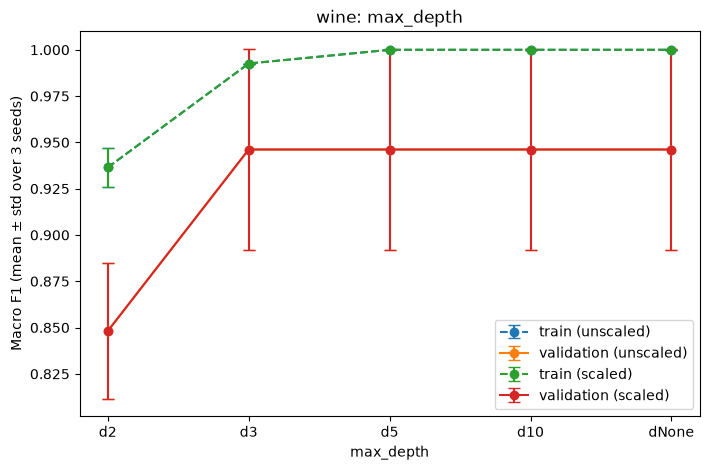

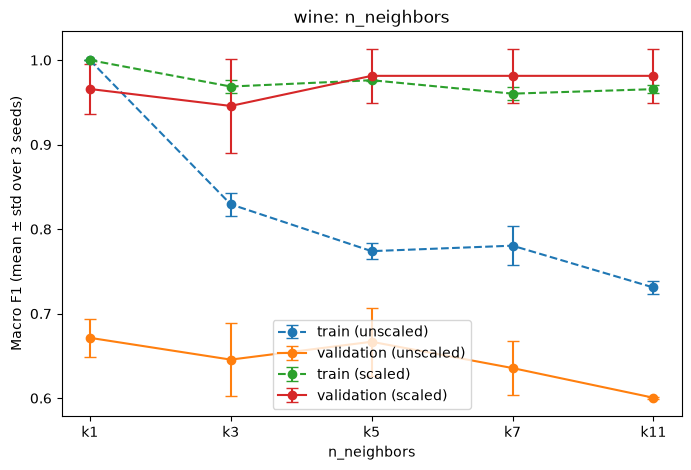

In [94]:
# bir algoritmanın parametresine göre ortalama train ve validation F1'ini çizer, hata çubukları = seed std
def parametre_grafigi(algo, etiketler, xlabel, dosya):
    plt.figure(figsize=(8, 5))
    for rep in ["unscaled", "scaled"]:
        alt = summary[(summary["algorithm"] == algo) & (summary["representation"] == rep)]
        alt = alt.set_index("param").loc[etiketler]
        plt.errorbar(etiketler, alt["train_f1_mean"], yerr=alt["train_f1_std"],
                     marker="o", linestyle="--", capsize=4, label=f"train ({rep})")
        plt.errorbar(etiketler, alt["val_f1_mean"], yerr=alt["val_f1_std"],
                     marker="o", capsize=4, label=f"validation ({rep})")
    plt.xlabel(xlabel)
    plt.ylabel("Macro F1 (mean ± std over 3 seeds)")
    plt.title(f"{DATASET}: {xlabel}")
    plt.legend()
    plt.savefig(dosya, bbox_inches="tight")
    plt.show()

parametre_grafigi("dt", ["d2", "d3", "d5", "d10", "dNone"], "max_depth", "figures/wine_tree_depth.png")
parametre_grafigi("knn", ["k1", "k3", "k5", "k7", "k11"], "n_neighbors", "figures/wine_knn_neighbors.png")

# 9. Evaluating the Selected Models on the Test Sets
## 9.1 Final performance metrics

In [95]:
# seçilen konfigürasyonun seed 42 modelini ve doğru veri versiyonunu al
best_row = secim.iloc[0]
final_model = models_s42[best_config]
if best_row["representation"] == "scaled":
    X_test_final = X_test_scaled
else:
    X_test_final = X_test

# 8. bölümdeki fonksiyonla test metriklerini hesapla, isimleri test_ yap
test_metrikleri = hesapla_metrikler(final_model, X_test_final, y_test)
test_metrikleri = {k.replace("val_", "test_"): v for k, v in test_metrikleri.items()}

classifier_test = pd.DataFrame([{
    "dataset": DATASET, "selected_config": best_config, "evaluation_seed": 42,
    "val_f1_mean": best_row["val_f1_mean"], "val_f1_std": best_row["val_f1_std"],
    "test_accuracy": test_metrikleri["test_accuracy"],
    "test_precision": test_metrikleri["test_precision"],
    "test_recall": test_metrikleri["test_recall"],
    "test_f1": test_metrikleri["test_f1"],
    "test_roc_auc": test_metrikleri["test_roc_auc"]}])
classifier_test

,dataset,selected_config,evaluation_seed,val_f1_mean,val_f1_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,wine,wine_knn_scaled_k11,42,0.981352,0.032299,1.0,1.0,1.0,1.0,1.0


In [96]:
test_tahmin = final_model.predict(X_test_final)
print(classification_report(y_test, test_tahmin, target_names=load_data.target_names, digits=4))

              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



### Test Sonuçlarının Değerlendirilmesi

Validation sonuçlarına göre seçilen `wine_knn_scaled_k11` konfigürasyonunun seed 42 modeli, sabit test kümesi üzerinde değerlendirilmiştir.

Test kümesinde toplam 36 şarap örneği bulunmaktadır. Önceki çalıştırma sonuçlarında accuracy, macro precision, macro recall, macro F1 ve macro ROC-AUC (OvR) değerlerinin tamamı **1.0000** olarak hesaplanmıştır.

Model, test kümesindeki 36 örneğin tamamını doğru sınıflandırmıştır. Validation aşamasındaki ortalama macro F1 yaklaşık 0.9814, test macro F1 ise 1.0000 olmuştur.

Model seçimi validation sonuçlarına göre yapılmış, test sonuçlarına bakılarak herhangi bir hiperparametre değişikliği yapılmamıştır.

Bu yüksek performans yalnızca kullanılan test kümesindeki sonucu göstermektedir; modelin farklı verilerde her zaman hatasız çalışacağını garanti etmez.

## 9.2 Confusion matrices

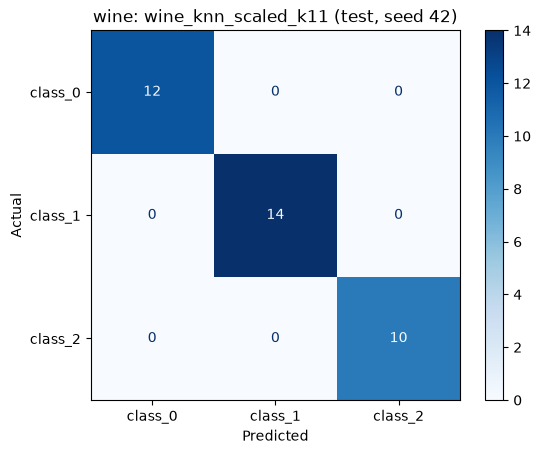

array([[12,  0,  0],
       [ 0, 14,  0],
       [ 0,  0, 10]])

In [97]:
# Wine sınıfları [0, 1, 2]; satırlar gerçek, sütunlar tahmin edilen sınıflar
cm = confusion_matrix(y_test, test_tahmin, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=load_data.target_names).plot(cmap="Blues", values_format="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{DATASET}: {best_config} (test, seed 42)")
plt.savefig("figures/wine_confusion_matrix.png", bbox_inches="tight")
plt.show()
cm

In [98]:
# class 1'i seçtim: class 1 vs diğer sınıflar
c = 1
TP = cm[c, c]
FN = cm[c, :].sum() - TP    # gerçekte class 1 olup başka tahmin edilenler
FP = cm[:, c].sum() - TP    # class 1 tahmin edilip aslında başka olanlar
precision_c = TP / (TP + FP) if (TP + FP) > 0 else float("nan")
recall_c = TP / (TP + FN) if (TP + FN) > 0 else float("nan")
f1_c = 2 * precision_c * recall_c / (precision_c + recall_c)
print("TP:", TP, "FN:", FN, "FP:", FP)
print("class 1 precision:", round(precision_c, 4))
print("class 1 recall:", round(recall_c, 4))
print("class 1 F1:", round(f1_c, 4))

TP: 14 FN: 0 FP: 0
class 1 precision: 1.0
class 1 recall: 1.0
class 1 F1: 1.0


### Confusion Matrix ve Manuel Metrik Hesaplama

Wine veri seti üç sınıflıdır. Confusion matrix üzerinde satırlar gerçek sınıfları, sütunlar ise tahmin edilen sınıfları göstermektedir.

Manuel hesaplama için sınıf 1 pozitif, diğer iki sınıf negatif kabul edilmiştir (One-vs-Rest).

- TP = 14
- FN = 0
- FP = 0
- TN = 22

**Precision:** 14 / (14 + 0) = 1.0000

**Recall:** 14 / (14 + 0) = 1.0000

**F1:** 2 × (1.0000 × 1.0000) / (1.0000 + 1.0000) = 1.0000

Bu sonuçlar classification report tablosundaki sınıf 1 değerleriyle tutarlıdır. Manuel hesaplama yalnızca sınıf 1 için yapılmıştır; macro ortalama değildir.

## 9.3 ROC curves

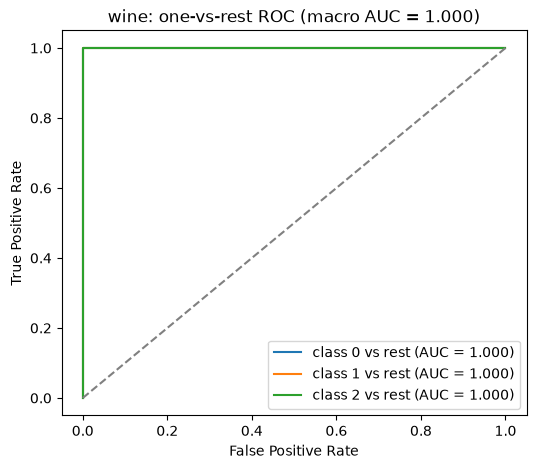

In [99]:
olasiliklar = final_model.predict_proba(X_test_final)
plt.figure(figsize=(6, 5))
for c in final_model.classes_:
    idx = list(final_model.classes_).index(c)
    hedef = (y_test == c).astype(int)               # bu sınıf 1, diğerleri 0
    fpr, tpr, _ = roc_curve(hedef, olasiliklar[:, idx])
    auc_c = roc_auc_score(hedef, olasiliklar[:, idx])
    plt.plot(fpr, tpr, label=f"class {c} vs rest (AUC = {auc_c:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"wine: one-vs-rest ROC (macro AUC = {test_metrikleri['test_roc_auc']:.3f})")
plt.legend()
plt.savefig("figures/wine_roc_curves.png", bbox_inches="tight")
plt.show()

Wine veri setinde üç sınıf bulunduğu için ROC eğrileri One-vs-Rest (OvR) yaklaşımıyla çizilmiştir. Her sınıf sırayla pozitif, diğer iki sınıf negatif kabul edilerek ayrı ROC eğrileri oluşturulmuştur.

Önceki test sonuçlarında macro ROC-AUC değeri 1.0000 olarak hesaplanmıştır. Bu sonuç, modelin test kümesinde sınıfları birbirinden çok başarılı şekilde ayırdığını göstermektedir.

ROC eğrileri, farklı sınıflandırma eşiklerinde True Positive Rate ve False Positive Rate değerlerinin nasıl değiştiğini göstermektedir.

Bu çalışmada sınıflandırma eşikleri test sonuçlarına göre değiştirilmemiştir. ROC grafikleri yalnızca seçilen modelin performansını değerlendirmek amacıyla kullanılmıştır.

## 9.4 Error interpretation

In [ ]:

# Wine test kümesindeki yanlış sınıflandırılan örnekler
hatalar = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": np.asarray(test_tahmin)
}, index=X_test.index)

hatalar = hatalar[
    hatalar["actual"] != hatalar["predicted"]
]

print("Hatalı tahmin sayısı:", len(hatalar))

display(
    hatalar.join(
        X_test[["alcohol", "flavanoids", "color_intensity"]]
    )
)


Hatalı tahmin sayısı: 0


,actual,predicted,alcohol,flavanoids,color_intensity


### Test Hatalarının Değerlendirilmesi

Önceki test sonuçlarında seçilen `wine_knn_scaled_k11` modeli, 36 şarap örneğinin tamamını doğru sınıflandırmıştır. Bu nedenle test kümesinde yanlış tahmin edilen örnek bulunmamaktadır.

Confusion matrix incelendiğinde üç sınıfın da doğru tahmin edildiği görülmektedir. Hatalı tahmin bulunmadığından belirli bir örnek üzerinden yanlış sınıflandırma analizi yapılamamıştır.

Bununla birlikte, test kümesindeki hatasız sonuç modelin bütün yeni verilerde aynı başarıyı göstereceği anlamına gelmez.

Çalışmanın bazı sınırlamaları bulunmaktadır. Wine veri seti toplam 178 örnekten oluşmaktadır ve her seed için validation kümesinde yalnızca 18 örnek vardır. Ayrıca üç farklı seed ile oluşturulan eğitim ve validation kümeleri tamamen bağımsız değildir.

Son test değerlendirmesi yalnızca validation sonuçlarına göre seçilen konfigürasyonun seed 42 modeliyle gerçekleştirilmiştir. Bu nedenle elde edilen 1.0000 test macro F1 değeri, kullanılan test kümesindeki performans olarak yorumlanmalıdır.

# 10. K-Means Clustering
## 10.1 Fit the clustering model

In [101]:
N_CLUSTERS = len(np.unique(Y))   # Wine veri setinde 3 sınıf olduğu için 3 küme

# silhouette en az 2 farklı küme ister ve küme sayısı örnek sayısından az olmalı, değilse NaN
def guvenli_silhouette(Xs, kumeler):
    k = len(np.unique(kumeler))
    if 2 <= k < len(Xs):
        return silhouette_score(Xs, kumeler)
    return np.nan

km_runs = []
kmeans_s42 = {}   # seed 42 modelleri test için
for seed in SEEDS:
    for rep in ["unscaled", "scaled"]:
        if rep == "unscaled":
            Xtr, Xv = splits[seed]["X_train"], splits[seed]["X_val"]
        else:
            Xtr, Xv = splits[seed]["X_train_scaled"], splits[seed]["X_val_scaled"]
        yv = splits[seed]["y_val"]

        km = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        km.fit(Xtr)                      # y verilmiyor, sadece özellikler
        val_kume = km.predict(Xv)
        km_runs.append({"run_id": f"{DATASET}_kmeans_{rep}_s{seed}", "dataset": DATASET,
                        "seed": seed, "representation": rep,
                        "train_inertia": km.inertia_,
                        "val_ari": adjusted_rand_score(yv, val_kume),
                        "val_silhouette": guvenli_silhouette(Xv, val_kume)})
        if seed == 42:
            kmeans_s42[rep] = km

kmeans_runs = pd.DataFrame(km_runs)
kmeans_runs

,run_id,dataset,seed,representation,train_inertia,val_ari,val_silhouette
0,wine_kmeans_unscaled_s42,wine,42,unscaled,1.350496e+06,0.282836,0.486994
1,wine_kmeans_scaled_s42,wine,42,scaled,8.747391e+02,1.000000,0.251637
2,wine_kmeans_unscaled_s52,wine,52,unscaled,1.303675e+06,0.400588,0.555887
3,wine_kmeans_scaled_s52,wine,52,scaled,8.904355e+02,1.000000,0.301008
4,wine_kmeans_unscaled_s62,wine,62,unscaled,1.390754e+06,0.400588,0.686671
5,wine_kmeans_scaled_s62,wine,62,scaled,8.722466e+02,1.000000,0.272587


In [102]:
# inertia'yı scaled ve unscaled arasında karşılaştırmıyoruz, birimleri farklı
kmeans_summary = kmeans_runs.groupby("representation").agg(
    train_inertia_mean=("train_inertia", "mean"), train_inertia_std=("train_inertia", "std"),
    val_ari_mean=("val_ari", "mean"), val_ari_std=("val_ari", "std"),
    val_silhouette_mean=("val_silhouette", "mean"), val_silhouette_std=("val_silhouette", "std"),
    valid_silhouette_count=("val_silhouette", "count")).reset_index()
kmeans_summary.insert(0, "dataset", DATASET)
kmeans_summary

,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_silhouette_count
0,wine,scaled,8.791404e+02,9.860948,1.000000,0.000000,0.275077,0.024780,3
1,wine,unscaled,1.348308e+06,43580.909759,0.361337,0.067984,0.576517,0.101425,3


### K-Means Validation Sonuçlarının Değerlendirilmesi

Wine veri setinde K-Means algoritması, üç farklı seed (42, 52 ve 62) için hem ölçeklendirilmemiş (unscaled) hem de ölçeklendirilmiş (scaled) eğitim verisi üzerinde çalıştırılmıştır. Böylece toplam 6 K-Means modeli eğitilmiştir.

Küme sayısı, Wine veri setindeki gerçek sınıf sayısına uygun olarak 3 seçilmiştir. Eğitim sırasında gerçek sınıf etiketleri (`y_train`) kullanılmamıştır.

Validation sonuçlarında ARI (Adjusted Rand Index), oluşturulan kümelerin gerçek sınıflarla ne kadar uyumlu olduğunu ölçmek için kullanılmıştır. Silhouette skoru ise gerçek sınıf etiketlerinden bağımsız olarak kümelerin kendi içindeki ayrışmasını değerlendirmiştir.

Ölçeklendirme K-Means için önemlidir. Wine veri setindeki `proline` gibi sayısal aralığı büyük özellikler, ölçeklendirilmemiş uzaklık hesaplarında daha baskın olabilir.

Silhouette ve inertia değerleri, scaled ve unscaled temsillerde farklı uzaklık ölçekleri kullanıldığı için doğrudan karşılaştırılmamalıdır.

Üç seed üzerindeki ortalama ve standart sapmalar, `kmeans_summary` tablosunda raporlanmıştır. Bu sonuçlar farklı eğitim ve validation bölmelerinin kümeleme performansı üzerindeki etkisini göstermektedir.

## 10.2 Final cluster evaluation on the fixed test sets

In [103]:
km_test = []
test_kumeler = {}
for rep in ["unscaled", "scaled"]:
    Xt = X_test if rep == "unscaled" else X_test_scaled
    kume = kmeans_s42[rep].predict(Xt)
    test_kumeler[rep] = kume
    sayimlar = pd.Series(kume).value_counts().sort_index()
    km_test.append({"dataset": DATASET, "representation": rep, "seed": 42,
                    "test_cluster_counts": str(sayimlar.to_dict()),
                    "test_ari": adjusted_rand_score(y_test, kume),
                    "test_silhouette": guvenli_silhouette(Xt, kume)})
kmeans_test = pd.DataFrame(km_test)
kmeans_test

,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette
0,wine,unscaled,42,"{0: 14, 1: 10, 2: 12}",0.373323,0.49288
1,wine,scaled,42,"{0: 13, 1: 13, 2: 10}",0.908794,0.27112


In [104]:
# Wine: Gerçek sınıflar ile K-Means kümelerinin karşılaştırılması
for rep in ["unscaled", "scaled"]:
    print(f"\n{rep.upper()} - Gerçek sınıf / Küme tablosu")

    tablo = pd.crosstab(
        pd.Series(np.asarray(y_test), name="Gerçek sınıf"),
        pd.Series(test_kumeler[rep], name="K-Means kümesi")
    )

    display(tablo)


UNSCALED - Gerçek sınıf / Küme tablosu


K-Means kümesi,0,1,2
Gerçek sınıf,,,
0,2,10,0
1,5,0,9
2,7,0,3



SCALED - Gerçek sınıf / Küme tablosu


K-Means kümesi,0,1,2
Gerçek sınıf,,,
0,12,0,0
1,1,13,0
2,0,0,10


### K-Means Test Sonuçlarının Değerlendirilmesi

Validation aşamasından sonra seed 42 ile eğitilen K-Means modelleri, yeniden eğitilmeden sabit Wine test kümesi üzerinde değerlendirilmiştir.

Test kümesinde toplam 36 şarap örneği ve 3 gerçek sınıf bulunmaktadır.

Önceki çalıştırma sonuçlarına göre:

- Unscaled K-Means test ARI: **0.3733**
- Scaled K-Means test ARI: **0.9088**

Bu sonuçlar, ölçeklendirilmiş özelliklerle oluşturulan kümelerin gerçek Wine sınıflarıyla daha yüksek uyum gösterdiğini ortaya koymaktadır.

Unscaled modelin test kümesi dağılımı 14, 10 ve 12 örnekten oluşan üç kümedir. Scaled modelin küme dağılımı ise 13, 13 ve 10 örnektir.

Ancak küme numaraları (0, 1, 2) gerçek sınıf numaralarıyla doğrudan aynı anlama gelmez. Örneğin küme 0'ın mutlaka gerçek sınıf 0'a karşılık gelmesi beklenmez.

Bu nedenle K-Means sonuçları sınıflandırma accuracy metriğiyle değil, ARI ve silhouette skorlarıyla değerlendirilmiştir.

K-Means algoritması eğitim sırasında gerçek sınıf etiketlerini kullanmamıştır. Gerçek etiketler yalnızca kümeleme sonuçlarının değerlendirilmesi için kullanılmıştır.

## 10.3 Visualise and interpret the clusters

Seçilen özellikler: flavanoids ve od280/od315_of_diluted_wines


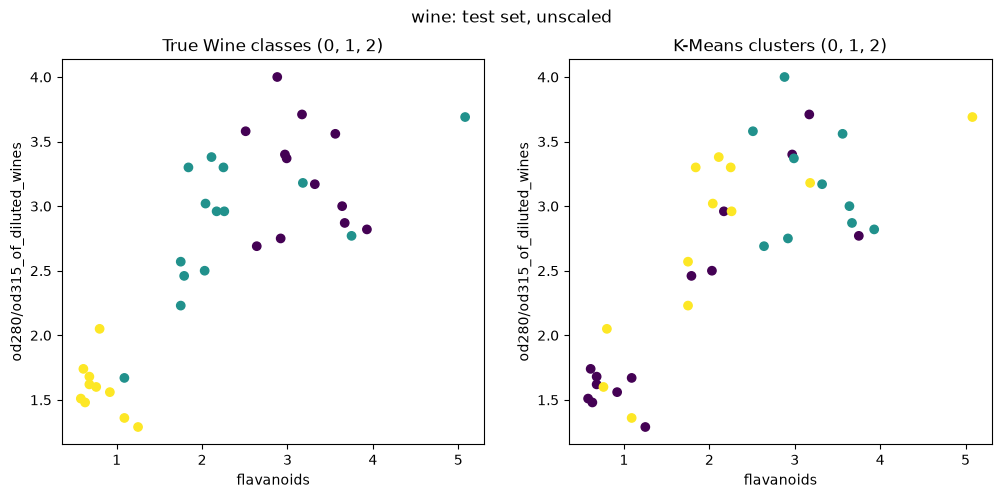

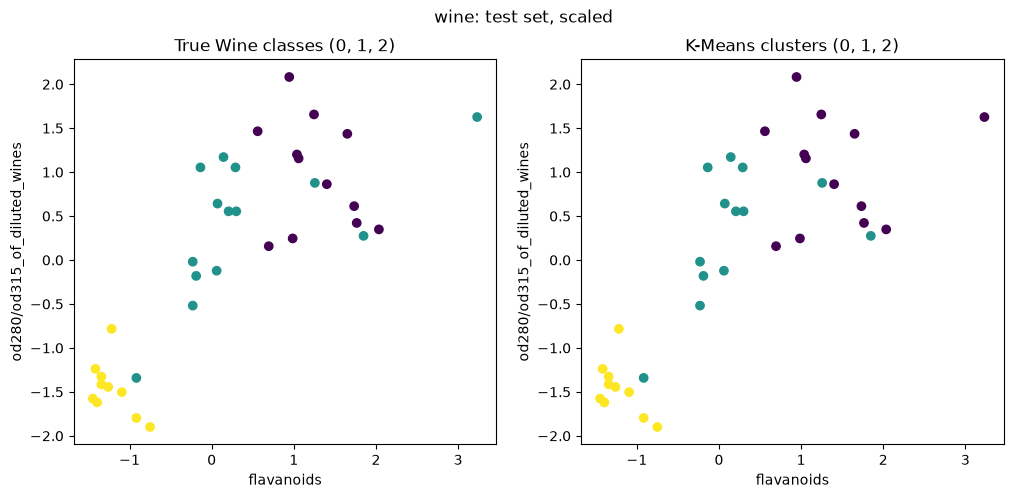

In [105]:

# Seed 42 eğitim verisinde sınıf etiketiyle en güçlü
# mutlak korelasyona sahip iki özelliği görselleştirme için seç
tr42 = splits[42]["X_train"]
y_kor = tr42.corrwith(
    pd.Series(splits[42]["y_train"], index=tr42.index)
).abs()

f1, f2 = y_kor.sort_values(ascending=False).index[:2]
print("Seçilen özellikler:", f1, "ve", f2)

for rep in ["unscaled", "scaled"]:
    Xt = X_test if rep == "unscaled" else X_test_scaled

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].scatter(Xt[f1], Xt[f2], c=y_test, cmap="viridis")
    ax[0].set_title("True Wine classes (0, 1, 2)")

    ax[1].scatter(
        Xt[f1], Xt[f2],
        c=test_kumeler[rep],
        cmap="viridis"
    )
    ax[1].set_title("K-Means clusters (0, 1, 2)")

    for a in ax:
        a.set_xlabel(f1)
        a.set_ylabel(f2)

    fig.suptitle(f"{DATASET}: test set, {rep}")
    plt.savefig(
        f"figures/{DATASET}_kmeans_{rep}.png",
        bbox_inches="tight"
    )
    plt.show()


### K-Means Küme Grafiklerinin Yorumlanması

Grafiklerde kullanılacak iki özellik, seed 42 eğitim verisinde gerçek sınıf etiketleriyle en yüksek mutlak korelasyona sahip özellikler arasından seçilmiştir. Seçilen özelliklerin isimleri, hemen üstteki grafik kodu çalıştırıldığında ekrana yazdırılmaktadır.

K-Means modelleri yalnızca bu iki özellik kullanılarak eğitilmemiştir. Modeller Wine veri setindeki 13 özelliğin tamamını kullanmaktadır. İki boyutlu grafikler ise kümelerin görsel olarak incelenmesi amacıyla hazırlanmıştır.

Test sonuçlarında ölçeklendirilmiş K-Means modelinin ARI değeri yaklaşık 0.9088, ölçeklendirilmemiş modelin ARI değeri ise yaklaşık 0.3733 olmuştur. Bu sonuç, ölçeklendirilmiş modelin oluşturduğu kümelerin gerçek sınıflarla daha yüksek uyum gösterdiğini ortaya koymaktadır.

Wine veri setinde `proline` gibi büyük sayısal değerlere sahip özellikler bulunmaktadır. Ölçeklendirme yapılmadığında bu özellikler Öklid uzaklığına dayalı K-Means algoritmasını daha fazla etkileyebilir.

Decision Tree, KNN ve Gaussian Naive Bayes algoritmaları denetimli öğrenme yöntemleridir ve eğitim sırasında gerçek sınıf etiketlerini kullanırlar. K-Means ise denetimsiz öğrenme yöntemidir; eğitim sırasında sınıf etiketlerini kullanmaz.

Gerçek sınıf etiketleri yalnızca ARI hesaplaması, contingency tabloları ve grafiklerde karşılaştırma yapılması amacıyla kullanılmıştır.


In [106]:
# sonuç tablolarını CSV olarak kaydet (Wine notebook'u da kendi tablolarını ekleyecek)
runs_df.to_csv("wine_classifier_runs.csv", index=False)
summary.to_csv("wine_classifier_summary.csv", index=False)
classifier_test.to_csv("wine_classifier_test.csv", index=False)
kmeans_runs.to_csv("wine_kmeans_runs.csv", index=False)
kmeans_summary.to_csv("wine_kmeans_summary.csv", index=False)
kmeans_test.to_csv("wine_kmeans_test.csv", index=False)

## Combined result files


In [107]:
# bc ve wine sonuçlarını birleştirip ödevin istediği 6 CSV'yi oluşturur
dosyalar = ["classifier_runs", "classifier_summary", "classifier_test",
            "kmeans_runs", "kmeans_summary", "kmeans_test"]
for isim in dosyalar:
    bc = pd.read_csv(f"bc_{isim}.csv")
    wn = pd.read_csv(f"wine_{isim}.csv")
    birlesik = pd.concat([bc, wn], ignore_index=True)   # alt alta ekle
    birlesik.to_csv(f"{isim}.csv", index=False)
    print(isim, len(birlesik), "satır")

classifier_runs 132 satır
classifier_summary 44 satır
classifier_test 2 satır
kmeans_runs 12 satır
kmeans_summary 4 satır
kmeans_test 4 satır


In [108]:

import os
import pandas as pd

dosyalar = [
    "classifier_runs",
    "classifier_summary",
    "classifier_test",
    "kmeans_runs",
    "kmeans_summary",
    "kmeans_test"
]

beklenen_satirlar = [132, 44, 2, 12, 4, 4]

for isim, beklenen in zip(dosyalar, beklenen_satirlar):
    yol = f"{isim}.csv"

    if not os.path.exists(yol):
        print(f"EKSİK: {yol}")
        continue

    tablo = pd.read_csv(yol)
    durum = "OK" if len(tablo) == beklenen else "KONTROL ET"

    print(
        f"{durum}: {yol} | "
        f"{len(tablo)} satır | "
        f"{len(tablo.columns)} sütun"
    )


OK: classifier_runs.csv | 132 satır | 16 sütun
OK: classifier_summary.csv | 44 satır | 19 sütun
OK: classifier_test.csv | 2 satır | 10 sütun
OK: kmeans_runs.csv | 12 satır | 7 sütun
OK: kmeans_summary.csv | 4 satır | 9 sütun
OK: kmeans_test.csv | 4 satır | 6 sütun
